<a href="https://colab.research.google.com/github/Adhityayusuf/mesin-learning/blob/main/JS06/JS06_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import library
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Membaca dataset
df = pd.read_csv('voice.csv')

# Menampilkan 5 data pertama
display(df.head())

# Menampilkan informasi dataset
print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

# Mengecek jumlah setiap kelas
print("\nJumlah data setiap kelas:")
print(df['label'].value_counts())


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran dataset: (3168, 21)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-nul

In [3]:

# Memisahkan fitur dan target
X = df.drop('label', axis=1)
y = df['label']

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Kelas target:", y.unique())


Jumlah fitur: 20
Jumlah data: 3168
Kelas target: ['male' 'female']


In [4]:

# Menyimpan hasil pengujian
hasil = []

# Rasio pembagian data
rasio_data = [
    (0.30, "70:30"),
    (0.20, "80:20")
]

# Jenis kernel SVM
jenis_kernel = ['linear', 'poly', 'rbf']

# Melakukan pengujian setiap rasio
for test_size, rasio in rasio_data:

    # Membagi data training dan testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # Menguji setiap jenis kernel
    for kernel in jenis_kernel:

        # Membuat pipeline normalisasi dan SVM
        model = Pipeline([
            ('scaler', StandardScaler()),
            ('svm', SVC(kernel=kernel))
        ])

        # Melatih model
        model.fit(X_train, y_train)

        # Melakukan prediksi
        y_pred = model.predict(X_test)

        # Menghitung akurasi
        akurasi = accuracy_score(y_test, y_pred)

        # Menyimpan hasil
        hasil.append({
            'Rasio Data': rasio,
            'Kernel': kernel,
            'Akurasi': akurasi,
            'Akurasi (%)': round(akurasi * 100, 2)
        })

        print(f"Rasio: {rasio} | Kernel: {kernel}")
        print(f"Akurasi: {akurasi * 100:.2f}%")
        print("-" * 40)


Rasio: 70:30 | Kernel: linear
Akurasi: 97.90%
----------------------------------------
Rasio: 70:30 | Kernel: poly
Akurasi: 96.00%
----------------------------------------
Rasio: 70:30 | Kernel: rbf
Akurasi: 98.32%
----------------------------------------
Rasio: 80:20 | Kernel: linear
Akurasi: 97.48%
----------------------------------------
Rasio: 80:20 | Kernel: poly
Akurasi: 95.58%
----------------------------------------
Rasio: 80:20 | Kernel: rbf
Akurasi: 98.26%
----------------------------------------


In [5]:

# Membuat tabel hasil evaluasi
tabel_hasil = pd.DataFrame(hasil)

display(tabel_hasil)


,Rasio Data,Kernel,Akurasi,Akurasi (%)
0,70:30,linear,0.978970,97.90
1,70:30,poly,0.960042,96.00
2,70:30,rbf,0.983176,98.32
3,80:20,linear,0.974763,97.48
4,80:20,poly,0.955836,95.58
5,80:20,rbf,0.982650,98.26


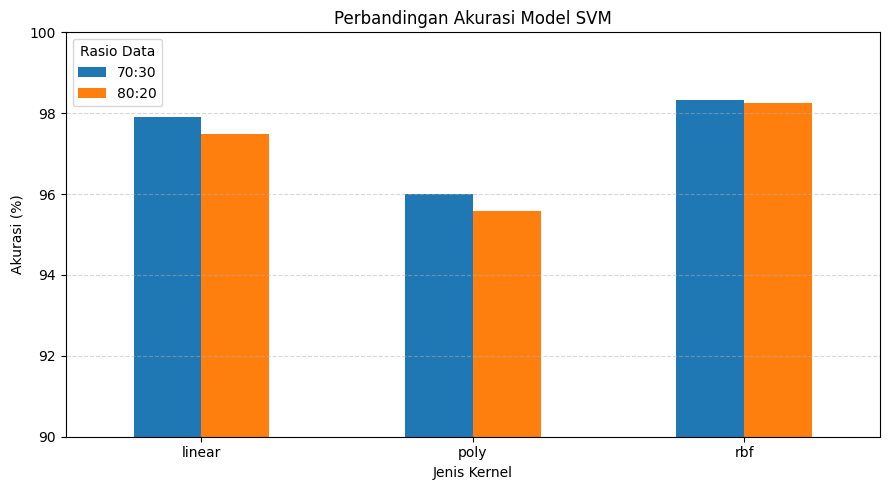

In [6]:

import matplotlib.pyplot as plt

# Mengubah hasil menjadi tabel untuk grafik
pivot_hasil = tabel_hasil.pivot(
    index='Kernel',
    columns='Rasio Data',
    values='Akurasi (%)'
)

# Membuat grafik
pivot_hasil.plot(kind='bar', figsize=(9, 5))

plt.title('Perbandingan Akurasi Model SVM')
plt.xlabel('Jenis Kernel')
plt.ylabel('Akurasi (%)')
plt.xticks(rotation=0)
plt.ylim(90, 100)
plt.legend(title='Rasio Data')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [7]:
   !unzip -q images.zip
   !ls images

test  training


In [8]:
train_dir = "images/training/"
test_dir = "images/test/"

In [11]:
import os
import cv2

def load_images_from_folder(folder_path):
    """
    Membaca semua gambar dari folder dan subfolder di dalamnya
    dan mengembalikan list tuple berupa (gambar, nama_kelas)
    """
    img_list = []
    # Mendapatkan daftar subfolder (nama kelas, misal: 'day', 'night')
    class_names = [d for d in os.listdir(folder_path) if os.path.isdir(os.path.join(folder_path, d))]

    for class_name in class_names:
        class_path = os.path.join(folder_path, class_name)
        for filename in os.listdir(class_path):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
                img_path = os.path.join(class_path, filename)
                img = cv2.imread(img_path)
                if img is not None:
                    # Mengubah format BGR bawaan OpenCV ke RGB
                    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_list.append((img_rgb, class_name))
    return img_list

def preprocess(img_list):
    """
    Melakukan preprocessing dengan menyamakan ukuran seluruh gambar menjadi 128x128 piksel
    """
    std_images = []
    for img, label in img_list:
        resized_img = cv2.resize(img, (128, 128))
        std_images.append((resized_img, label))
    return std_images

# Memuat semua data gambar
train_img = load_images_from_folder(train_dir)
test_img = load_images_from_folder(test_dir)

print(f"Berhasil memuat {len(train_img)} gambar training.")
print(f"Berhasil memuat {len(test_img)} gambar testing.")

Berhasil memuat 240 gambar training.
Berhasil memuat 160 gambar testing.


In [19]:
from sklearn.model_selection import train_test_split

# Menggabungkan data
semua_img = train_img + test_img

# Preprocessing gambar
semua_std_img = preprocess(semua_img)

# Ekstraksi fitur histogram
df_hist = extract_histogram_feature(semua_std_img)


# Memisahkan fitur dan target gambar
X_images = df_hist.drop('LABELS', axis=1)
y_images = df_hist['LABELS']

# Membagi data gambar 80:20
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_images,
    y_images,
    test_size=0.20,
    random_state=42,
    stratify=y_images
)

print("Jumlah seluruh data:", len(df_hist))
print("Data training:", len(X_train_img))
print("Data testing:", len(X_test_img))
print("Jumlah fitur histogram:", X_train_img.shape[1])

Jumlah seluruh data: 400
Data training: 320
Data testing: 80
Jumlah fitur histogram: 32


In [20]:

# Import library
import cv2
import numpy as np
import pandas as pd

# Fungsi ekstraksi fitur histogram
def extract_histogram_feature(img_list):
    features = []
    labels = []

    for img, label in img_list:
        # Mengubah gambar RGB menjadi grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        # Menghitung histogram dengan 32 bin
        hist = cv2.calcHist(
            [gray], [0], None, [32], [0, 256]
        )

        # Normalisasi histogram
        hist = cv2.normalize(hist, hist).flatten()

        # Menyimpan fitur dan label
        features.append(hist)
        labels.append(label)

    # Membuat DataFrame
    kolom = [f'HIST_{i}' for i in range(32)]
    df_hist = pd.DataFrame(features, columns=kolom)
    df_hist['LABELS'] = labels

    return df_hist


In [21]:

from sklearn.model_selection import train_test_split

# Menggabungkan data dari praktikum 5
semua_img = train_img + test_img

# Preprocessing gambar
semua_std_img = preprocess(semua_img)

# Ekstraksi fitur histogram
df_hist = extract_histogram_feature(semua_std_img)

# Memisahkan fitur dan label
X = df_hist.drop('LABELS', axis=1)
y = df_hist['LABELS']

# Split data dengan rasio 80:20
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Jumlah seluruh data:", len(df_hist))
print("Data training:", len(X_train))
print("Data testing:", len(X_test))
print("Jumlah fitur histogram:", X_train.shape[1])


Jumlah seluruh data: 400
Data training: 320
Data testing: 80
Jumlah fitur histogram: 32


In [22]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

# Pipeline normalisasi dan model SVM RBF
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf'))
])

# Kombinasi parameter yang akan diuji
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.001, 0.01, 0.1, 1]
}

# Hyperparameter tuning dengan cross-validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Melatih model menggunakan data training
grid_search.fit(X_train, y_train)

# Menampilkan parameter terbaik
print("Parameter terbaik:")
print(grid_search.best_params_)

print("\nAkurasi cross-validation terbaik:")
print(f"{grid_search.best_score_ * 100:.2f}%")

# Mengambil model terbaik
best_model = grid_search.best_estimator_


Parameter terbaik:
{'svm__C': 10, 'svm__gamma': 'scale'}

Akurasi cross-validation terbaik:
99.38%


In [23]:

# Prediksi data training
y_train_pred = best_model.predict(X_train)

# Prediksi data testing
y_test_pred = best_model.predict(X_test)

# Menghitung akurasi
acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test, y_test_pred)

# Menampilkan hasil
print("=== HASIL KLASIFIKASI SIANG DAN MALAM ===")
print(f"Akurasi Training : {acc_train * 100:.2f}%")
print(f"Akurasi Testing  : {acc_test * 100:.2f}%")


=== HASIL KLASIFIKASI SIANG DAN MALAM ===
Akurasi Training : 99.69%
Akurasi Testing  : 98.75%


              precision    recall  f1-score   support

       Night       0.98      1.00      0.99        40
         Day       1.00      0.97      0.99        40

    accuracy                           0.99        80
   macro avg       0.99      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



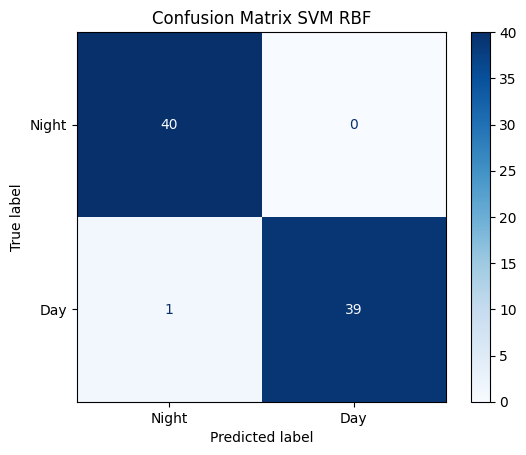

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

# Laporan klasifikasi pada data testing dengan label string yang benar
print(classification_report(
    y_test,
    y_test_pred,
    labels=['night', 'day'],
    target_names=['Night', 'Day'],
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=['night', 'day'],
    display_labels=['Night', 'Day'],
    cmap='Blues'
)

plt.title('Confusion Matrix SVM RBF')
plt.show()